In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import ReduceLROnPlateau
import gc

print("PyTorch version:", torch.__version__)
print("GPU available  :", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device   :", device)

PyTorch version: 2.10.0+cu128
GPU available  : True
Using device   : cuda


In [2]:
train_df   = pd.read_csv('/kaggle/input/competitions/Kannada-MNIST/train.csv')
test_df    = pd.read_csv('/kaggle/input/competitions/Kannada-MNIST/test.csv')
dig_df     = pd.read_csv('/kaggle/input/competitions/Kannada-MNIST/Dig-MNIST.csv')
sample_sub = pd.read_csv('/kaggle/input/competitions/Kannada-MNIST/sample_submission.csv')

print(f"Train    : {train_df.shape}")
print(f"Test     : {test_df.shape}")
print(f"Dig-MNIST: {dig_df.shape}")

Train    : (60000, 785)
Test     : (5000, 785)
Dig-MNIST: (10240, 785)


/tmp/ipykernel_57/780520810.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=y_counts.index, y=y_counts.values, palette="Blues_d")


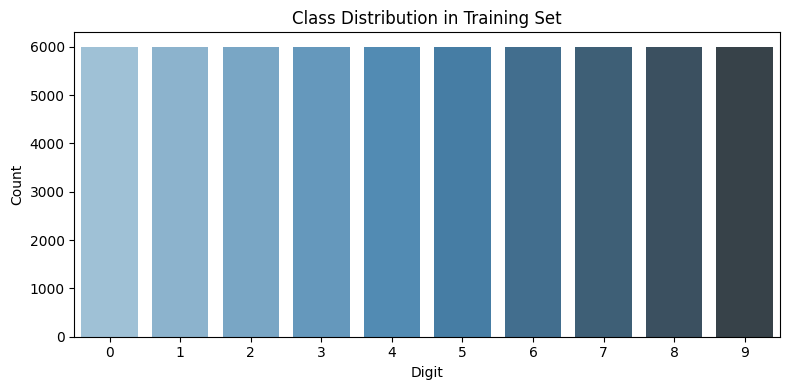

label
0    6000
1    6000
2    6000
3    6000
4    6000
5    6000
6    6000
7    6000
8    6000
9    6000
Name: count, dtype: int64


In [3]:
plt.figure(figsize=(8, 4))
y_counts = train_df['label'].value_counts().sort_index()
sns.barplot(x=y_counts.index, y=y_counts.values, palette="Blues_d")
plt.title("Class Distribution in Training Set")
plt.xlabel("Digit")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print(y_counts)

## Data Splits
- **Train set**: 85% of `train.csv`
- **Validation set**: 15% of `train.csv`
- **Test set**: `Dig-MNIST.csv` (used for final accuracy & confusion matrix)
- **Kaggle submission**: `test.csv` (unlabelled, for submission only)

In [4]:
# Extract features and labels from train.csv
X = train_df.drop('label', axis=1).values.reshape(-1, 1, 28, 28).astype(np.float32) / 255.0
y = train_df['label'].values.astype(np.int64)
del train_df
gc.collect()

# Test set = Dig-MNIST (has labels)
X_test = dig_df.drop('label', axis=1).values.reshape(-1, 1, 28, 28).astype(np.float32) / 255.0
y_test = dig_df['label'].values.astype(np.int64)
del dig_df
gc.collect()

# Kaggle submission set (no labels)
test_ids      = test_df['id'].values
X_kaggle      = test_df.drop('id', axis=1).values.reshape(-1, 1, 28, 28).astype(np.float32) / 255.0
del test_df
gc.collect()

print(f"X             : {X.shape}")
print(f"X_test (Dig)  : {X_test.shape}  ← labelled test set")
print(f"X_kaggle      : {X_kaggle.shape}  ← no labels, submission only")

X             : (60000, 1, 28, 28)
X_test (Dig)  : (10240, 1, 28, 28)  ← labelled test set
X_kaggle      : (5000, 1, 28, 28)  ← no labels, submission only


In [5]:
# Split train.csv into Train (85%) and Validation (15%)
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
del X, y
gc.collect()

print(f"Train samples      : {X_train.shape[0]}")
print(f"Validation samples : {X_val.shape[0]}")
print(f"Test samples (Dig) : {X_test.shape[0]}")

Train samples      : 51000
Validation samples : 9000
Test samples (Dig) : 10240


In [6]:
from torchvision import transforms

# Augmentation only for training
train_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomRotation(10),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(),
])

val_transforms = transforms.Compose([
    transforms.ToPILImage(),
    transforms.ToTensor(),
])

class KannadaDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images    = images
        self.labels    = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = (self.images[idx].squeeze(0) * 255).astype(np.uint8)
        if self.transform:
            img = self.transform(img)
        else:
            img = torch.tensor(self.images[idx], dtype=torch.float32)
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return img, label

train_dataset = KannadaDataset(X_train, y_train, transform=train_transforms)
val_dataset   = KannadaDataset(X_val,   y_val,   transform=val_transforms)
test_dataset  = KannadaDataset(X_test,  y_test,  transform=val_transforms)

_pin = device.type == 'cuda'
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True,  num_workers=2, pin_memory=_pin)
val_loader   = DataLoader(val_dataset,   batch_size=64, shuffle=False, num_workers=2, pin_memory=_pin)
test_loader  = DataLoader(test_dataset,  batch_size=64, shuffle=False, num_workers=2, pin_memory=_pin)

print(f"Train batches : {len(train_loader)}")
print(f"Val batches   : {len(val_loader)}")
print(f"Test batches  : {len(test_loader)}")

Train batches : 797
Val batches   : 141
Test batches  : 160


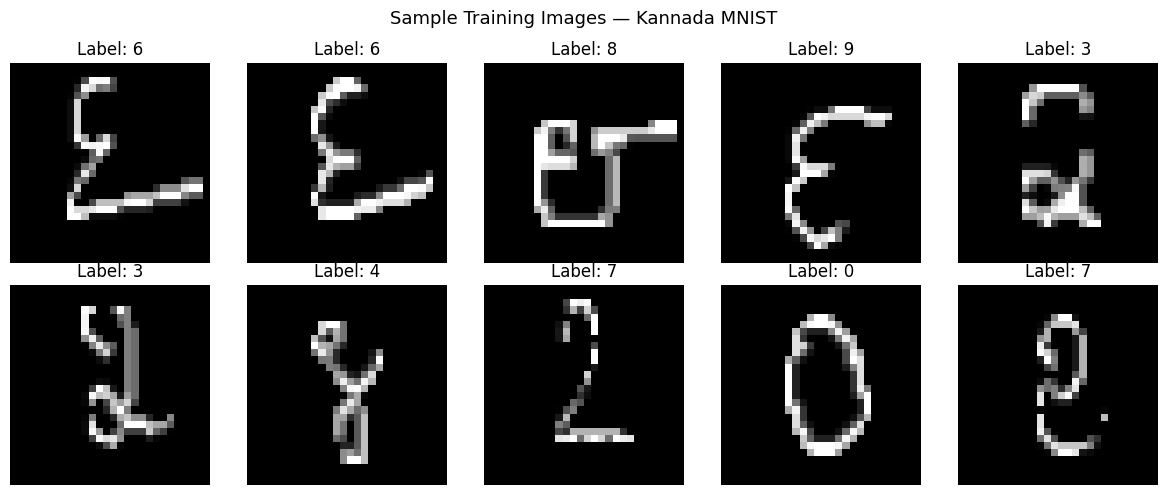

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle("Sample Training Images — Kannada MNIST", fontsize=13)

for i, ax in enumerate(axes.flatten()):
    ax.imshow(X_train[i, 0], cmap='gray')
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis('off')

plt.tight_layout()
plt.show()

In [8]:
class KannadaCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(KannadaCNN, self).__init__()

        # Block 1
        self.block1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.BatchNorm2d(32, momentum=0.15),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.25)
        )

        # Block 2
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(64, momentum=0.15),
            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.25)
        )

        # Block 3
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(128, momentum=0.15),
            nn.Dropout2d(0.25)
        )

        # Classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.classifier(x)
        return x


# Sanity check
model = KannadaCNN(num_classes=10)
dummy = torch.zeros(1, 1, 28, 28)
print("Output shape:", model(dummy).shape)  # torch.Size([1, 10])

Output shape: torch.Size([1, 10])


In [9]:
# ── Model Trainable Parameter Count ──────────────────────────────────────────
def count_parameters(model):
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

total_params, trainable_params = count_parameters(model)
print(f"Total parameters     : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print(f"Non-trainable params : {total_params - trainable_params:,}")

Total parameters     : 1,764,650
Trainable parameters : 1,764,650
Non-trainable params : 0


In [10]:
def evaluate(model, loader, device):
    model.eval()
    total, correct, total_loss = 0, 0, 0.0
    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss    = criterion(outputs, labels)
            _, preds = outputs.max(1)

            total_loss += loss.item() * labels.size(0)
            correct    += (preds == labels).sum().item()
            total      += labels.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total
    return avg_loss, accuracy

In [11]:
def train_model(model, train_loader, val_loader,
                epochs=30, lr=0.001,
                patience=7,
                device='cpu',
                checkpoint_path='/kaggle/working/best_model.pt'):

    model     = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, betas=(0.9, 0.999))
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5,
                                  patience=3, min_lr=1e-5)

    train_losses, val_losses         = [], []
    train_accuracies, val_accuracies = [], []

    best_val_loss    = float('inf')
    best_epoch       = 0
    patience_counter = 0

    torch.save(model.state_dict(), checkpoint_path)

    for epoch in range(epochs):
        # --- Train ---
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss    = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            _, preds      = outputs.max(1)
            correct      += (preds == labels).sum().item()
            total        += labels.size(0)

        train_loss = running_loss / total
        train_acc  = correct / total

        # --- Validate ---
        val_loss, val_acc = evaluate(model, val_loader, device)

        scheduler.step(val_loss)

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)

        print(f"Epoch {epoch+1:>2}/{epochs} | "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

        if val_loss < best_val_loss:
            best_val_loss    = val_loss
            best_epoch       = epoch + 1
            patience_counter = 0
            torch.save(model.state_dict(), checkpoint_path)
            print(f"  ✅ New best val_loss: {best_val_loss:.4f} — checkpoint saved")
        else:
            patience_counter += 1
            print(f"  ⏳ No improvement — patience {patience_counter}/{patience}")
            if patience_counter >= patience:
                print(f"\n🛑 Early stopping at epoch {epoch+1}. "
                      f"Best was epoch {best_epoch} with val_loss={best_val_loss:.4f}")
                break

    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    print(f"\n✅ Restored best weights from epoch {best_epoch}")

    return model, train_losses, val_losses, train_accuracies, val_accuracies

In [12]:
model = KannadaCNN(num_classes=10).to(device)

model, train_losses, val_losses, train_accs, val_accs = train_model(
    model, train_loader, val_loader,
    epochs=30,
    lr=0.001,
    patience=7,
    device=device,
    checkpoint_path='/kaggle/working/best_model.pt'
)

Epoch  1/30 | Train Loss: 0.2059 | Train Acc: 0.9347 | Val Loss: 0.0291 | Val Acc: 0.9926
  ✅ New best val_loss: 0.0291 — checkpoint saved
Epoch  2/30 | Train Loss: 0.0917 | Train Acc: 0.9731 | Val Loss: 0.0218 | Val Acc: 0.9929
  ✅ New best val_loss: 0.0218 — checkpoint saved
Epoch  3/30 | Train Loss: 0.0818 | Train Acc: 0.9771 | Val Loss: 0.0224 | Val Acc: 0.9933
  ⏳ No improvement — patience 1/7
Epoch  4/30 | Train Loss: 0.0694 | Train Acc: 0.9803 | Val Loss: 0.0169 | Val Acc: 0.9948
  ✅ New best val_loss: 0.0169 — checkpoint saved
Epoch  5/30 | Train Loss: 0.0659 | Train Acc: 0.9819 | Val Loss: 0.0206 | Val Acc: 0.9942
  ⏳ No improvement — patience 1/7
Epoch  6/30 | Train Loss: 0.0609 | Train Acc: 0.9830 | Val Loss: 0.0181 | Val Acc: 0.9947
  ⏳ No improvement — patience 2/7
Epoch  7/30 | Train Loss: 0.0559 | Train Acc: 0.9850 | Val Loss: 0.0135 | Val Acc: 0.9956
  ✅ New best val_loss: 0.0135 — checkpoint saved
Epoch  8/30 | Train Loss: 0.0529 | Train Acc: 0.9858 | Val Loss: 0.0152 

## Training Curves
Train vs Validation **Loss** and **Accuracy** plotted together.

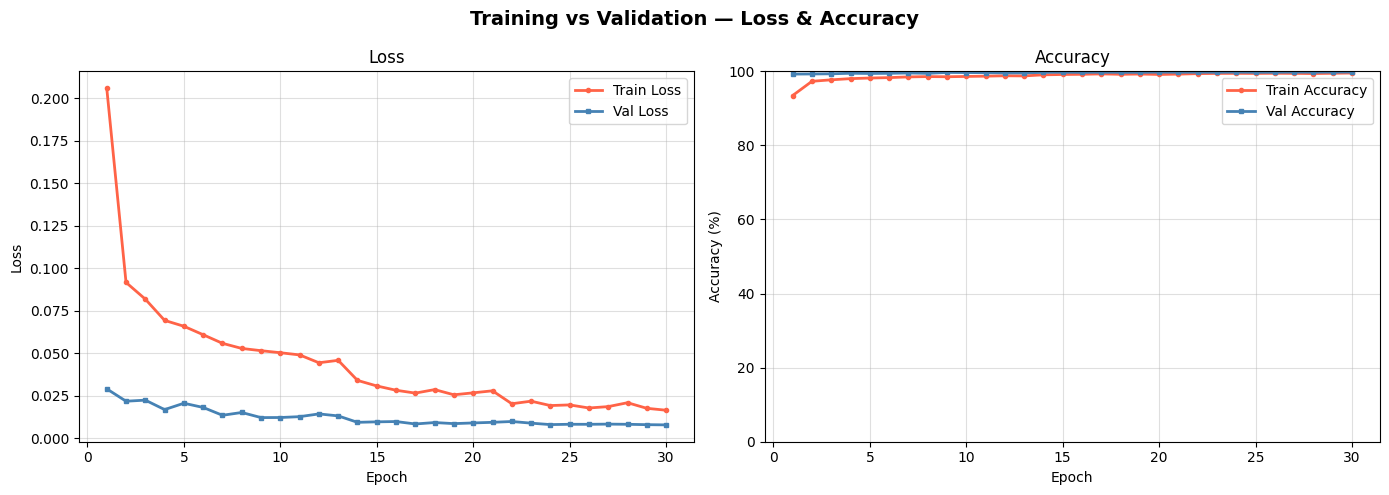

Plot saved to /kaggle/working/training_curves.png


In [13]:
epochs_ran = len(train_losses)
x = range(1, epochs_ran + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Training vs Validation — Loss & Accuracy", fontsize=14, fontweight='bold')

# ── Left: Loss ────────────────────────────────────────────────────────────────
ax1.plot(x, train_losses, color='tomato',      linewidth=2, marker='o', markersize=3, label='Train Loss')
ax1.plot(x, val_losses,   color='steelblue',   linewidth=2, marker='s', markersize=3, label='Val Loss')
ax1.set_title("Loss", fontsize=12)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()
ax1.grid(True, alpha=0.4)

# ── Right: Accuracy ───────────────────────────────────────────────────────────
ax2.plot(x, [a * 100 for a in train_accs], color='tomato',    linewidth=2, marker='o', markersize=3, label='Train Accuracy')
ax2.plot(x, [a * 100 for a in val_accs],   color='steelblue', linewidth=2, marker='s', markersize=3, label='Val Accuracy')
ax2.set_title("Accuracy", fontsize=12)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.set_ylim(0, 100)
ax2.legend()
ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig('/kaggle/working/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot saved to /kaggle/working/training_curves.png")

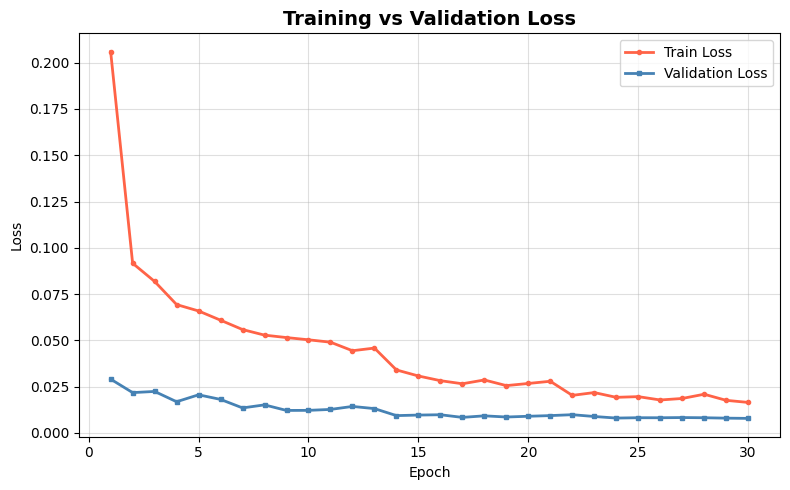

Loss plot saved to /kaggle/working/loss_plot.png


In [22]:
epochs_ran = len(train_losses)
x = range(1, epochs_ran + 1)

plt.figure(figsize=(8, 5))

# ── Loss Plot ────────────────────────────────────────────────────────────────
plt.plot(
    x,
    train_losses,
    color='tomato',
    linewidth=2,
    marker='o',
    markersize=3,
    label='Train Loss'
)

plt.plot(
    x,
    val_losses,
    color='steelblue',
    linewidth=2,
    marker='s',
    markersize=3,
    label='Validation Loss'
)

plt.title("Training vs Validation Loss", fontsize=14, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True, alpha=0.4)

plt.tight_layout()

plt.savefig(
    '/kaggle/working/loss_plot.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

print("Loss plot saved to /kaggle/working/loss_plot.png")

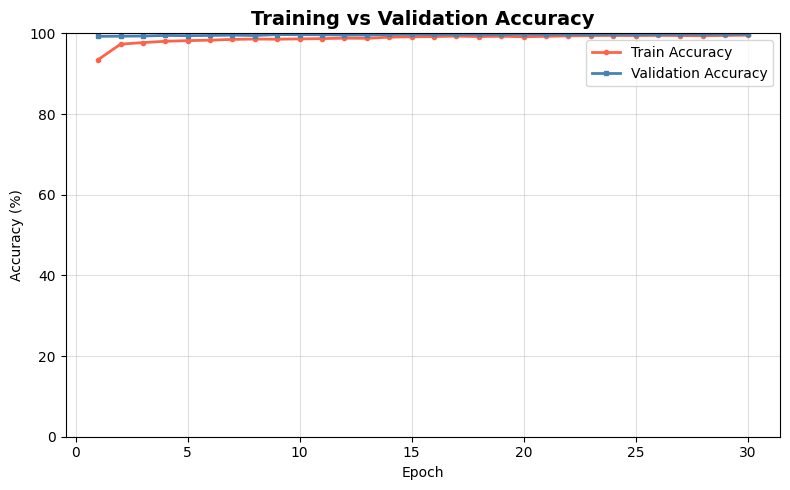

Accuracy plot saved to /kaggle/working/accuracy_plot.png


In [23]:
epochs_ran = len(train_accs)
x = range(1, epochs_ran + 1)

plt.figure(figsize=(8, 5))

# ── Accuracy Plot ────────────────────────────────────────────────────────────
plt.plot(
    x,
    [a * 100 for a in train_accs],
    color='tomato',
    linewidth=2,
    marker='o',
    markersize=3,
    label='Train Accuracy'
)

plt.plot(
    x,
    [a * 100 for a in val_accs],
    color='steelblue',
    linewidth=2,
    marker='s',
    markersize=3,
    label='Validation Accuracy'
)

plt.title("Training vs Validation Accuracy", fontsize=14, fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)

plt.legend()
plt.grid(True, alpha=0.4)

plt.tight_layout()

plt.savefig(
    '/kaggle/working/accuracy_plot.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

print("Accuracy plot saved to /kaggle/working/accuracy_plot.png")

## Test Set Evaluation (Dig-MNIST)
Computing accuracy score on the held-out **Test set** (`Dig-MNIST.csv`).

In [15]:
def predict_loader(model, loader, device):
    """Returns numpy arrays of predicted and true class indices."""
    
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            _, preds = outputs.max(1)

            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.numpy())

    return np.concatenate(all_preds), np.concatenate(all_labels)


# ── Test set evaluation ───────────────────────────────────────────────────────
test_loss, test_acc_loop = evaluate(model, test_loader, device)

y_pred_test, y_true_test = predict_loader(model, test_loader, device)

# sklearn accuracy_score as the definitive metric
test_accuracy = accuracy_score(y_true_test, y_pred_test)

print("=" * 50)
print(f"  Test Loss     : {test_loss:.4f}")
print(f"  Test Accuracy : {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")
print("=" * 50)

  Test Loss     : 0.7842
  Test Accuracy : 0.8799 (87.99%)


## Confusion Matrix — Test Set

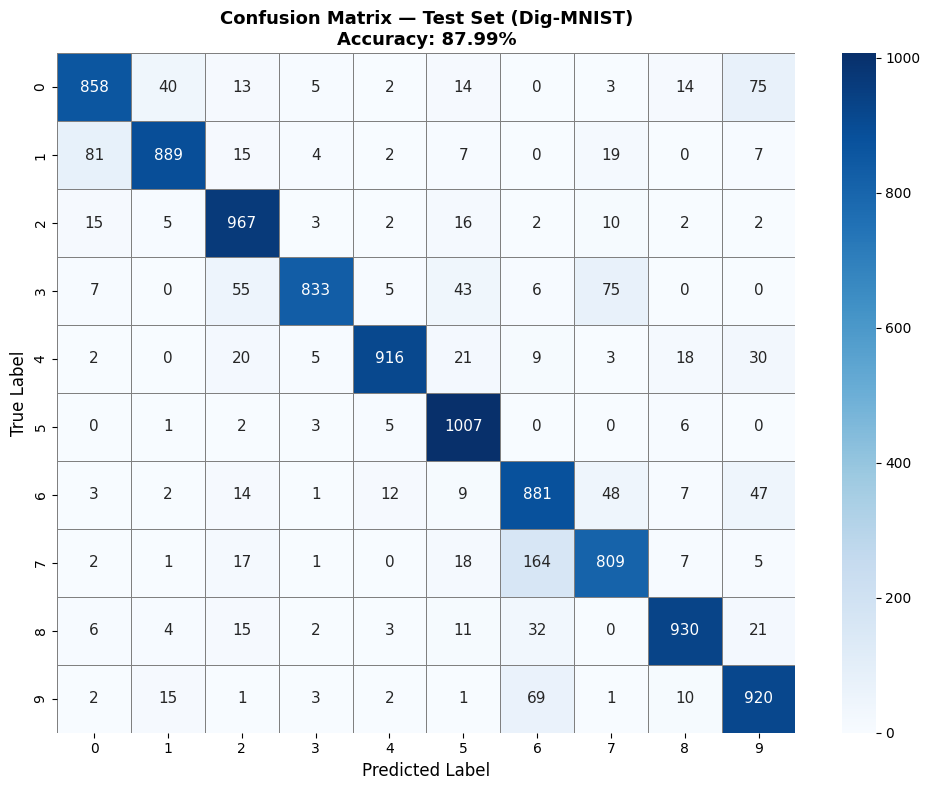

Confusion matrix saved to /kaggle/working/confusion_matrix_test.png


In [16]:
cm = confusion_matrix(y_true_test, y_pred_test)
cm_df = pd.DataFrame(cm, index=range(10), columns=range(10))

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_df, annot=True, fmt='d', cmap='Blues',
    annot_kws={"size": 11},
    linewidths=0.5, linecolor='gray'
)
plt.title(f"Confusion Matrix — Test Set (Dig-MNIST)\nAccuracy: {test_accuracy*100:.2f}%",
          fontsize=13, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrix_test.png', dpi=150, bbox_inches='tight')
plt.show()
print("Confusion matrix saved to /kaggle/working/confusion_matrix_test.png")

In [17]:
# Per-class accuracy breakdown
print("\nPer-class Accuracy:")
print("-" * 30)
for cls in range(10):
    mask       = y_true_test == cls
    cls_acc    = accuracy_score(y_true_test[mask], y_pred_test[mask])
    n_samples  = mask.sum()
    print(f"  Class {cls}: {cls_acc*100:6.2f}%  ({n_samples} samples)")


Per-class Accuracy:
------------------------------
  Class 0:  83.79%  (1024 samples)
  Class 1:  86.82%  (1024 samples)
  Class 2:  94.43%  (1024 samples)
  Class 3:  81.35%  (1024 samples)
  Class 4:  89.45%  (1024 samples)
  Class 5:  98.34%  (1024 samples)
  Class 6:  86.04%  (1024 samples)
  Class 7:  79.00%  (1024 samples)
  Class 8:  90.82%  (1024 samples)
  Class 9:  89.84%  (1024 samples)


Misclassified: 1230 / 10240


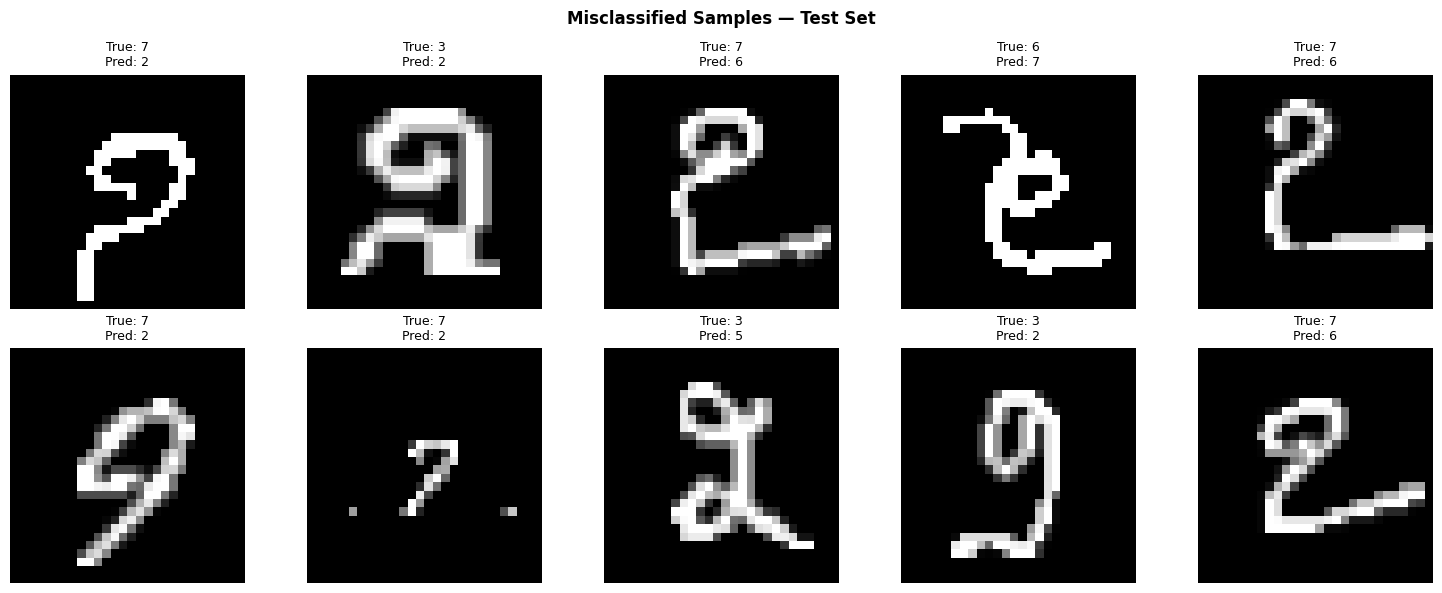

In [18]:
wrong_idx = np.where(y_pred_test != y_true_test)[0]
print(f"Misclassified: {len(wrong_idx)} / {len(y_true_test)}")

n_show = min(10, len(wrong_idx))
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle("Misclassified Samples — Test Set", fontsize=12, fontweight='bold')
for i, ax in enumerate(axes.flatten()):
    idx = wrong_idx[i]
    ax.imshow(X_test[idx, 0], cmap='gray')
    ax.set_title(f"True: {y_true_test[idx]}\nPred: {y_pred_test[idx]}", fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Kaggle Submission
Generating predictions on `test.csv` (unlabelled) for submission.

In [20]:
def predict_numpy(model, X_np, device, batch_size=256):
    """Run inference on a raw numpy array (N,1,28,28)."""
    
    model.eval()
    all_preds = []

    with torch.no_grad():
        for start in range(0, len(X_np), batch_size):
            batch = torch.tensor(
                X_np[start:start+batch_size],
                dtype=torch.float32
            ).to(device)

            outputs = model(batch)
            _, preds = outputs.max(1)

            all_preds.append(preds.cpu().numpy())

    return np.concatenate(all_preds)


y_pred_kaggle = predict_numpy(model, X_kaggle, device)

sample_sub['label'] = y_pred_kaggle

sample_sub.to_csv('/kaggle/working/submission.csv', index=False)

print("Submission saved to /kaggle/working/submission.csv")

display(sample_sub.head(10))

Submission saved to /kaggle/working/submission.csv


,id,label
0,0,3
1,1,0
2,2,2
3,3,6
4,4,7
5,5,7
6,6,1
7,7,9
8,8,2
9,9,4


In [21]:
MODEL_PATH = '/kaggle/working/kannada_mnist_model.pt'
torch.save(model.state_dict(), MODEL_PATH)
print(f"Model saved to {MODEL_PATH}")

# To reload:
#   model = KannadaCNN(num_classes=10)
#   model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
#   model.eval()

Model saved to /kaggle/working/kannada_mnist_model.pt
